# Preprocess Splits For Cold Start Evaluation #

In [26]:
import os
import sys
sys.path.append("/home/gavrilev/Thesis/src")

%load_ext autoreload
%autoreload 2
    
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from scipy.stats import ks_2samp



from utils.plot_utils import *
from utils.tools import set_seed

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
ALL_SFM_DATA = '/home/gavrilev/Thesis/src/datasets/RSIM/All_sf_dataset_v1.csv'
UNIQUE_RSIM_SMILES = '/home/gavrilev/Thesis/src/saved_objects/rsim_unique_smiles.pkl' # rsim unique smiles list
AUG_RSIM_SMILES = '/home/gavrilev/Thesis/src/saved_objects/rsim_aug_smiles.pkl' # augmented smiles list
SMILES2AUG_PATH = '/home/gavrilev/Thesis/src/saved_objects/smiles2aug.pkl' # dictionary that maps smiles -> smiles aug list 

COLD_PATH = '/home/gavrilev/Thesis/src/datasets/blind_test/'
COLD_PATH_RNA_SAVE = '/home/gavrilev/Thesis/src/datasets/blind_test/rna/train_test_splits/'
COLD_PATH_SMI_SAVE = '/home/gavrilev/Thesis/src/datasets/blind_test/mole/train_test_splits/'

RNA_COLD_PATH = '/home/gavrilev/Thesis/src/datasets/blind_test/rna/train_val_test_splits/'
MOLE_COLD_PATH = '/home/gavrilev/Thesis/src/datasets/blind_test/mole/train_val_test_splits/'

In [1]:
def load_cold_data(cold_type="cold_rna"):
    _ ,cold = cold_type.split('_')
    df1 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'1.csv', delimiter=',')
    df2 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'2.csv', delimiter=',')
    df3 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'3.csv', delimiter=',')
    df4 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'4.csv', delimiter=',')
    df5 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'5.csv', delimiter=',')
    cold_dfs = [df1, df2, df3, df4, df5]
    return cold_dfs

def get_cold_splits(curr_cold_df=None, cold_dfs=None, all_df=None, fold=0):
    """
    Generate train/test indices for a given cold-start fold.

    Args:
        curr_cold_df (pd.DataFrame): current fold dataframe used as test set.
        cold_dfs (list[pd.DataFrame]): list of all cold split dataframes.
        all_df (pd.DataFrame): full dataset containing Entry_ID column.
        fold (int): index of the current test fold.

    Returns:
        tuple[list[int], list[int]]: train indices, test indices.
    """
    if curr_cold_df is None or cold_dfs is None or all_df is None:
        raise ValueError("Either curr_cold_df/cold_dfs/all_df is None")

    test_id = curr_cold_df['Target_RNA_sequence'].tolist()
    test_id = all_df[all_df['Target_RNA_sequence'].isin(test_id)].index.tolist()

    train_id = []
    for j, other_df in enumerate(cold_dfs):
        if j != fold:
            train_id.extend(other_df['Target_RNA_sequence'].tolist())

    train_id = all_df[all_df['Target_RNA_sequence'].isin(train_id)].index.tolist()
    return train_id, test_id

In [4]:
def get_unique_smiles_rnas():
    all_sfm_df = pd.read_csv(ALL_SFM_DATA, delimiter='\t')
    unique_smiles, unique_rnas = set(list(all_sfm_df['SMILES'])), set(list(all_sfm_df['Target_RNA_sequence']))
    return unique_smiles, unique_rnas

def save_pkl(obj, path):
    with open(path, "wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
def load_pkl(path):
    with open(path, "rb") as f:
        result = pickle.load(f)
    return result

In [17]:
def gen_cold_folds(colds_dfs, full_df, cold_column):
    cold_folds = []
    for i in range(5):
        print('###################')
        train_id, test_id = get_cold_splits(curr_cold_df=colds_dfs[i], cold_dfs=colds_dfs, all_df=full_df, fold=i)
        curr_train_df = full_df.iloc[train_id, :]
        curr_test_df = full_df.iloc[test_id, :]
        print(f'Fold -> {i+1}, train -> {curr_train_df.shape[0]}, test -> {curr_test_df.shape[0]}')
        overlap = set(curr_train_df[cold_column]) & set(curr_test_df[cold_column])
        assert len(overlap) == 0 # senaty check
        cold_folds.append((curr_train_df, curr_test_df))
    return cold_folds

In [28]:
def cold_val_splits(
    cold_folds,
    cold_column,
    save_path,
    cold_name,
    val_size=0.15,
    num_seeds=100,
    top_k=5
):
    candidates = []

    for curr_seed in range(num_seeds):
        curr_splits = []
        curr_fold_scores = []
        valid_seed = True

        for i in range(1, len(cold_folds) + 1):
            train_df = cold_folds[i - 1][0].copy()
            test_df = cold_folds[i - 1][1].copy()

            # make sure the cold column exists
            assert cold_column in train_df.columns
            assert cold_column in test_df.columns

            splitter = GroupShuffleSplit(
                n_splits=1,
                test_size=val_size,
                random_state=curr_seed
            )

            train_idx, val_idx = next(
                splitter.split(
                    train_df,
                    groups=train_df[cold_column]
                )
            )

            train_df_inner = train_df.iloc[train_idx].copy()
            val_df = train_df.iloc[val_idx].copy()

            ################################################################
            # validity checks
            ################################################################

            # 1. train/val must be cold by selected column
            overlap_train_val = (
                set(train_df_inner[cold_column])
                & set(val_df[cold_column])
            )

            # 2. train/test must stay cold by selected column
            overlap_train_test = (
                set(train_df_inner[cold_column])
                & set(test_df[cold_column])
            )

            # 3. val/test must also be cold by selected column
            overlap_val_test = (
                set(val_df[cold_column])
                & set(test_df[cold_column])
            )

            if (
                len(overlap_train_val) > 0
                or len(overlap_train_test) > 0
                or len(overlap_val_test) > 0
            ):
                valid_seed = False
                break

            # 4. train + val should equal original train size
            if len(train_df_inner) + len(val_df) != len(train_df):
                valid_seed = False
                break

            # 5. test should not change
            if len(test_df) != len(cold_folds[i - 1][1]):
                valid_seed = False
                break

            fold_score = score_pkd_distribution(
                train_df_inner,
                val_df,
                val_size=val_size
            )

            curr_splits.append((train_df_inner, val_df, test_df))
            curr_fold_scores.append(fold_score)

        if not valid_seed:
            continue

        avg_score = np.mean(curr_fold_scores)

        candidates.append({
            "seed": curr_seed,
            "avg_score": avg_score,
            "splits": curr_splits,
            "fold_scores": curr_fold_scores
        })

    candidates = sorted(candidates, key=lambda x: x["avg_score"])
    top_candidates = candidates[:top_k]

    if len(top_candidates) == 0:
        raise ValueError("No valid cold validation split was found.")

    ########################################################################
    # print top-k candidates
    ########################################################################
    for rank, candidate in enumerate(top_candidates, start=1):
        print("############################")
        print(f"Rank {rank}")
        print(f"Best seed: {candidate['seed']}")
        print(f"Best average distribution score: {candidate['avg_score']:.5f}")

        for i, (train_df_inner, val_df, test_df) in enumerate(candidate["splits"], start=1):
            real_val_ratio = len(val_df) / (len(train_df_inner) + len(val_df))

            print(
                f"Fold {i}: "
                f"train_inner={train_df_inner.shape[0]}, "
                f"val={val_df.shape[0]}, "
                f"test={test_df.shape[0]}, "
                f"val_ratio={real_val_ratio:.4f}, "
                f"unique_train_{cold_name}={train_df_inner[cold_column].nunique()}, "
                f"unique_val_{cold_name}={val_df[cold_column].nunique()}, "
                f"unique_test_{cold_name}={test_df[cold_column].nunique()}, "
                f"score={candidate['fold_scores'][i - 1]:.5f}"
            )

    ########################################################################
    # save best candidate only
    ########################################################################
    best_candidate = top_candidates[0]
    best_seed = best_candidate["seed"]
    best_splits = best_candidate["splits"]

    os.makedirs(save_path, exist_ok=True)

    for i, (train_df_inner, val_df, test_df) in enumerate(best_splits, start=1):

        # final sanity checks before saving
        assert len(set(train_df_inner[cold_column]) & set(val_df[cold_column])) == 0
        assert len(set(train_df_inner[cold_column]) & set(test_df[cold_column])) == 0
        assert len(set(val_df[cold_column]) & set(test_df[cold_column])) == 0

        original_train_df = cold_folds[i - 1][0]
        original_test_df = cold_folds[i - 1][1]

        assert len(train_df_inner) + len(val_df) == len(original_train_df)
        assert len(test_df) == len(original_test_df)

        train_df_inner.to_csv(
            os.path.join(save_path, f"cold_{cold_name}_train_fold{i}.csv"),
            index=False
        )

        val_df.to_csv(
            os.path.join(save_path, f"cold_{cold_name}_val_fold{i}.csv"),
            index=False
        )

        test_df.to_csv(
            os.path.join(save_path, f"cold_{cold_name}_test_fold{i}.csv"),
            index=False
        )

    print("############################")
    print(f"Saved best splits with seed={best_seed}")
    print(f"Saved to: {save_path}")

    scores_df = pd.DataFrame([
        {
            "rank": rank + 1,
            "seed": candidate["seed"],
            "avg_distribution_score": candidate["avg_score"]
        }
        for rank, candidate in enumerate(top_candidates)
    ])

    return best_splits, best_seed, scores_df, top_candidates

In [29]:
def score_pkd_distribution(train_df_inner, val_df, val_size=0.15, size_weight=10.0):
    train_y = train_df_inner["pKd"].dropna().values
    val_y = val_df["pKd"].dropna().values

    all_y = np.concatenate([train_y, val_y])
    global_std = np.std(all_y)

    if global_std == 0:
        global_std = 1.0

    ks_score = ks_2samp(train_y, val_y).statistic
    mean_diff = abs(np.mean(train_y) - np.mean(val_y)) / global_std
    std_diff = abs(np.std(train_y) - np.std(val_y)) / global_std

    total_size = len(train_df_inner) + len(val_df)
    real_val_ratio = len(val_df) / total_size
    size_penalty = abs(real_val_ratio - val_size)

    score = (
        ks_score
        + mean_diff
        + std_diff
        + size_weight * size_penalty
    )

    return score

In [5]:
all_sfm_df = pd.read_csv(ALL_SFM_DATA, delimiter='\t')
all_sfm_df.head()

,Entry_ID,SMILES,Target_RNA_sequence,Molecule_name,Molecule_ID,Target_RNA_name,Target_RNA_ID,pKd
0,2091,N[C@@H]1C[C@H](N)[C@H]([C@H]([C@H]1OCCCc1nnn(c...,CGCGCAGUCAGUAGCGCG,B-13,Target_lig_1138,RNA hairpin loop IV,Target_381,6.387216
1,162,C1CN(CCC1C(=O)NCCN2CCOCC2)CC3=CC=C(C=C3)Cl,GAGCGUCACACCUUCGGGUGAAGUCGCUC,1-(4-chlorobenzyl)-N-(2-morpholinoethyl)piperi...,Target_lig_132,A-site 16S rRNA_E_coli (1),Target_3,3.602060
2,270,c1c(ccc2Sc3ccccc3N(c12)CCCNCN(CO)CO)C(=O)C,GGCAGAUCUGAGCCUGGGAGCUCUCUGCC,3_phenothiazine_analog_1,Target_lig_210,HIV-1 TAR RNA,Target_19,2.522879
3,1327,C(CN1C=C(CNC2=C3C=CC=CC3=[NH+]C3=C2OC2=C3C=CC=...,GGGUUAGGGU,Quindoline CK1-14,Target_lig_723,TRF2:TERRA G-quadruplex (TERRA22):Telomeric du...,Target_262,6.272784
4,1907,C1=CC=C(C=C1)C2=NN=C(O2)C3=NC4=CC=CC=C4C(=N3)N...,UGUGGGAGGGGCGGGUCUGGG,NRAS SAR 7,Target_lig_1057,NRAS G4 motif,Target_259,6.443697


## Cold Small Molecule ##

In [14]:
cold_mole_dfs = load_cold_data(cold_type="cold_mole")
len(cold_mole_dfs)

5

In [20]:
# senaty check that verifies that DeepRSMA cold start setting is valid
for i in range(5):
    for j in range(i + 1, 5):
        overlap = set(cold_mole_dfs[i]['Molecule_name']) & set(cold_mole_dfs[j]['Molecule_name'])
        print(f"fold {i+1} vs fold {j+1}: {len(overlap)}")

fold 1 vs fold 2: 0
fold 1 vs fold 3: 0
fold 1 vs fold 4: 0
fold 1 vs fold 5: 0
fold 2 vs fold 3: 0
fold 2 vs fold 4: 0
fold 2 vs fold 5: 0
fold 3 vs fold 4: 0
fold 3 vs fold 5: 0
fold 4 vs fold 5: 0


In [21]:
set(cold_mole_dfs[0]['Molecule_name']).intersection(cold_mole_dfs[1]['Molecule_name']) # senaty check

set()

In [23]:
cold_folds = []
for i in range(5):
    print('###################')
    # molecules that should be in the test set for this fold
    test_molecules = set(cold_mole_dfs[i]['Molecule_name'].dropna())

    # all rows with these molecules go to test & all other rows go to train
    curr_test_df = all_sfm_df[all_sfm_df['Molecule_name'].isin(test_molecules)].copy()
    curr_train_df = all_sfm_df[~all_sfm_df['Molecule_name'].isin(test_molecules)].copy()

    print(f'Fold -> {i+1}, train -> {curr_train_df.shape[0]}, test -> {curr_test_df.shape[0]}')

    # sanity check: no same molecule in train and test
    overlap = set(curr_train_df['Molecule_name']) & set(curr_test_df['Molecule_name'])
    print(f'Molecule_name overlap: {len(overlap)}')
    assert len(overlap) == 0

    overlap = set(curr_train_df['Entry_ID']) & set(curr_test_df['Entry_ID'])
    print(f'Entry_ID overlap: {len(overlap)}')
    assert len(overlap) == 0

    cold_folds.append((curr_train_df, curr_test_df))

###################
Fold -> 1, train -> 1139, test -> 300
Molecule_name overlap: 0
Entry_ID overlap: 0
###################
Fold -> 2, train -> 1152, test -> 287
Molecule_name overlap: 0
Entry_ID overlap: 0
###################
Fold -> 3, train -> 1183, test -> 256
Molecule_name overlap: 0
Entry_ID overlap: 0
###################
Fold -> 4, train -> 1153, test -> 286
Molecule_name overlap: 0
Entry_ID overlap: 0
###################
Fold -> 5, train -> 1129, test -> 310
Molecule_name overlap: 0
Entry_ID overlap: 0


In [24]:
### save small molecule cold start setting train/test splits
os.makedirs(COLD_PATH_SMI_SAVE, exist_ok=True)

for i, (train_df, test_df) in enumerate(cold_folds, 1):
    train_df.to_csv(os.path.join(COLD_PATH_SMI_SAVE, f"cold_mole_train_fold{i}.csv"), index=False)
    test_df.to_csv(os.path.join(COLD_PATH_SMI_SAVE, f"cold_mole_test_fold{i}.csv"), index=False)

### Generate Cold Validation Splits ###

In [32]:
best_splits, best_seed, scores_df, top_candidates = cold_val_splits(
    cold_folds=cold_folds,
    cold_column="Molecule_name",
    save_path=MOLE_COLD_PATH,
    cold_name="mole",
    val_size=0.15,
    num_seeds=100,
    top_k=5
)

############################
Rank 1
Best seed: 52
Best average distribution score: 0.26405
Fold 1: train_inner=973, val=166, test=300, val_ratio=0.1457, unique_train_mole=549, unique_val_mole=98, unique_test_mole=161, score=0.37698
Fold 2: train_inner=985, val=167, test=287, val_ratio=0.1450, unique_train_mole=549, unique_val_mole=98, unique_test_mole=161, score=0.28642
Fold 3: train_inner=1012, val=171, test=256, val_ratio=0.1445, unique_train_mole=549, unique_val_mole=98, unique_test_mole=161, score=0.18547
Fold 4: train_inner=982, val=171, test=286, val_ratio=0.1483, unique_train_mole=549, unique_val_mole=98, unique_test_mole=161, score=0.14696
Fold 5: train_inner=952, val=177, test=310, val_ratio=0.1568, unique_train_mole=547, unique_val_mole=97, unique_test_mole=164, score=0.32440
############################
Rank 2
Best seed: 44
Best average distribution score: 0.26819
Fold 1: train_inner=969, val=170, test=300, val_ratio=0.1493, unique_train_mole=549, unique_val_mole=98, unique_

In [33]:
train_val_best_splits = [(train, val) for train, val, _ in best_splits]
#val_test_best_splits = [(val, test) for _, val, test in best_splits]

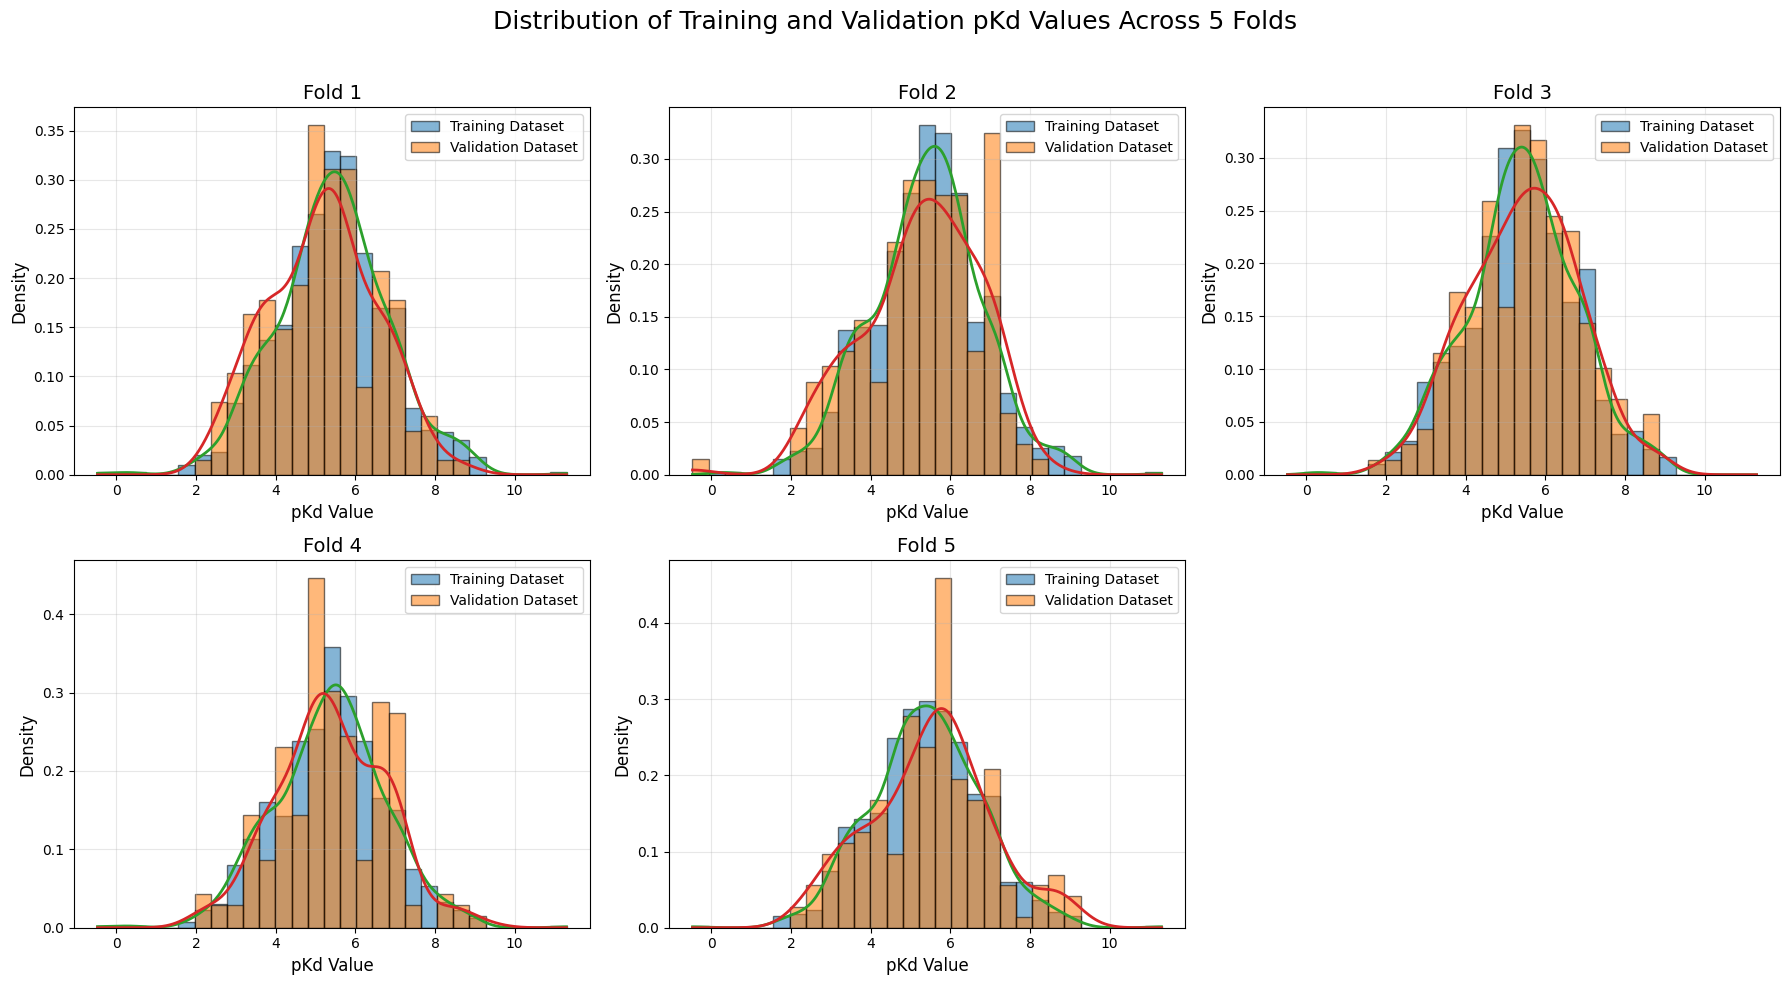

In [34]:
plot_all_folds_train_val_pkd_hist(
    train_val_best_splits
)

## Cold RNA ##

In [35]:
cold_rna_dfs = load_cold_data(cold_type="cold_rna")
len(cold_rna_dfs)

5

In [36]:
# senaty check that verifies that DeepRSMA cold start setting is valid
for i in range(5):
    for j in range(i + 1, 5):
        overlap = set(cold_rna_dfs[i]['Target_RNA_sequence']) & set(cold_rna_dfs[j]['Target_RNA_sequence'])
        print(f"fold {i+1} vs fold {j+1}: {len(overlap)}")

fold 1 vs fold 2: 0
fold 1 vs fold 3: 0
fold 1 vs fold 4: 0
fold 1 vs fold 5: 0
fold 2 vs fold 3: 0
fold 2 vs fold 4: 0
fold 2 vs fold 5: 0
fold 3 vs fold 4: 0
fold 3 vs fold 5: 0
fold 4 vs fold 5: 0


In [37]:
set(cold_rna_dfs[0]['Target_RNA_sequence']).intersection(cold_rna_dfs[1]['Target_RNA_sequence']) # senaty check

set()

In [38]:
cold_folds = []
for i in range(5):
    print('###################')
    train_id, test_id = get_cold_splits(curr_cold_df=cold_rna_dfs[i], cold_dfs=cold_rna_dfs, all_df=all_sfm_df, fold=i)
    curr_train_df = all_sfm_df.iloc[train_id, :]
    curr_test_df = all_sfm_df.iloc[test_id, :]
    print(f'Fold -> {i+1}, train -> {curr_train_df.shape[0]}, test -> {curr_test_df.shape[0]}')
    overlap = set(curr_train_df['Entry_ID']) & set(curr_test_df['Entry_ID'])
    assert len(overlap) == 0 # senaty check
    overlap = set(curr_train_df['Target_RNA_sequence']) & set(curr_test_df['Target_RNA_sequence'])
    assert len(overlap) == 0 # senaty check
    cold_folds.append((curr_train_df, curr_test_df))

###################
Fold -> 1, train -> 1256, test -> 183
###################
Fold -> 2, train -> 1196, test -> 243
###################
Fold -> 3, train -> 1134, test -> 305
###################
Fold -> 4, train -> 960, test -> 479
###################
Fold -> 5, train -> 1210, test -> 229


In [39]:
### save RNA cold start setting train/test splits
os.makedirs(COLD_PATH_RNA_SAVE, exist_ok=True)

for i, (train_df, test_df) in enumerate(cold_folds, 1):
    train_df.to_csv(os.path.join(COLD_PATH_RNA_SAVE, f"cold_rna_train_fold{i}.csv"), index=False)
    test_df.to_csv(os.path.join(COLD_PATH_RNA_SAVE, f"cold_rna_test_fold{i}.csv"), index=False)

### Generate Cold Validation Splits ###

In [40]:
best_splits, best_seed, scores_df, top_candidates = cold_val_splits(
    cold_folds=cold_folds,
    cold_column="Target_RNA_sequence",
    save_path=RNA_COLD_PATH,
    cold_name="rna",
    val_size=0.15,
    num_seeds=100,
    top_k=5
)

############################
Rank 1
Best seed: 32
Best average distribution score: 0.60659
Fold 1: train_inner=1062, val=194, test=183, val_ratio=0.1545, unique_train_rna=200, unique_val_rna=36, unique_test_rna=59, score=0.51092
Fold 2: train_inner=1014, val=182, test=243, val_ratio=0.1522, unique_train_rna=200, unique_val_rna=36, unique_test_rna=59, score=0.74020
Fold 3: train_inner=958, val=176, test=305, val_ratio=0.1552, unique_train_rna=200, unique_val_rna=36, unique_test_rna=59, score=0.83252
Fold 4: train_inner=839, val=121, test=479, val_ratio=0.1260, unique_train_rna=200, unique_val_rna=36, unique_test_rna=59, score=0.45842
Fold 5: train_inner=1034, val=176, test=229, val_ratio=0.1455, unique_train_rna=200, unique_val_rna=36, unique_test_rna=59, score=0.49087
############################
Rank 2
Best seed: 74
Best average distribution score: 0.63038
Fold 1: train_inner=1123, val=133, test=183, val_ratio=0.1059, unique_train_rna=200, unique_val_rna=36, unique_test_rna=59, score=

In [41]:
train_val_best_splits = [(train, val) for train, val, _ in best_splits]
#val_test_best_splits = [(val, test) for _, val, test in best_splits]

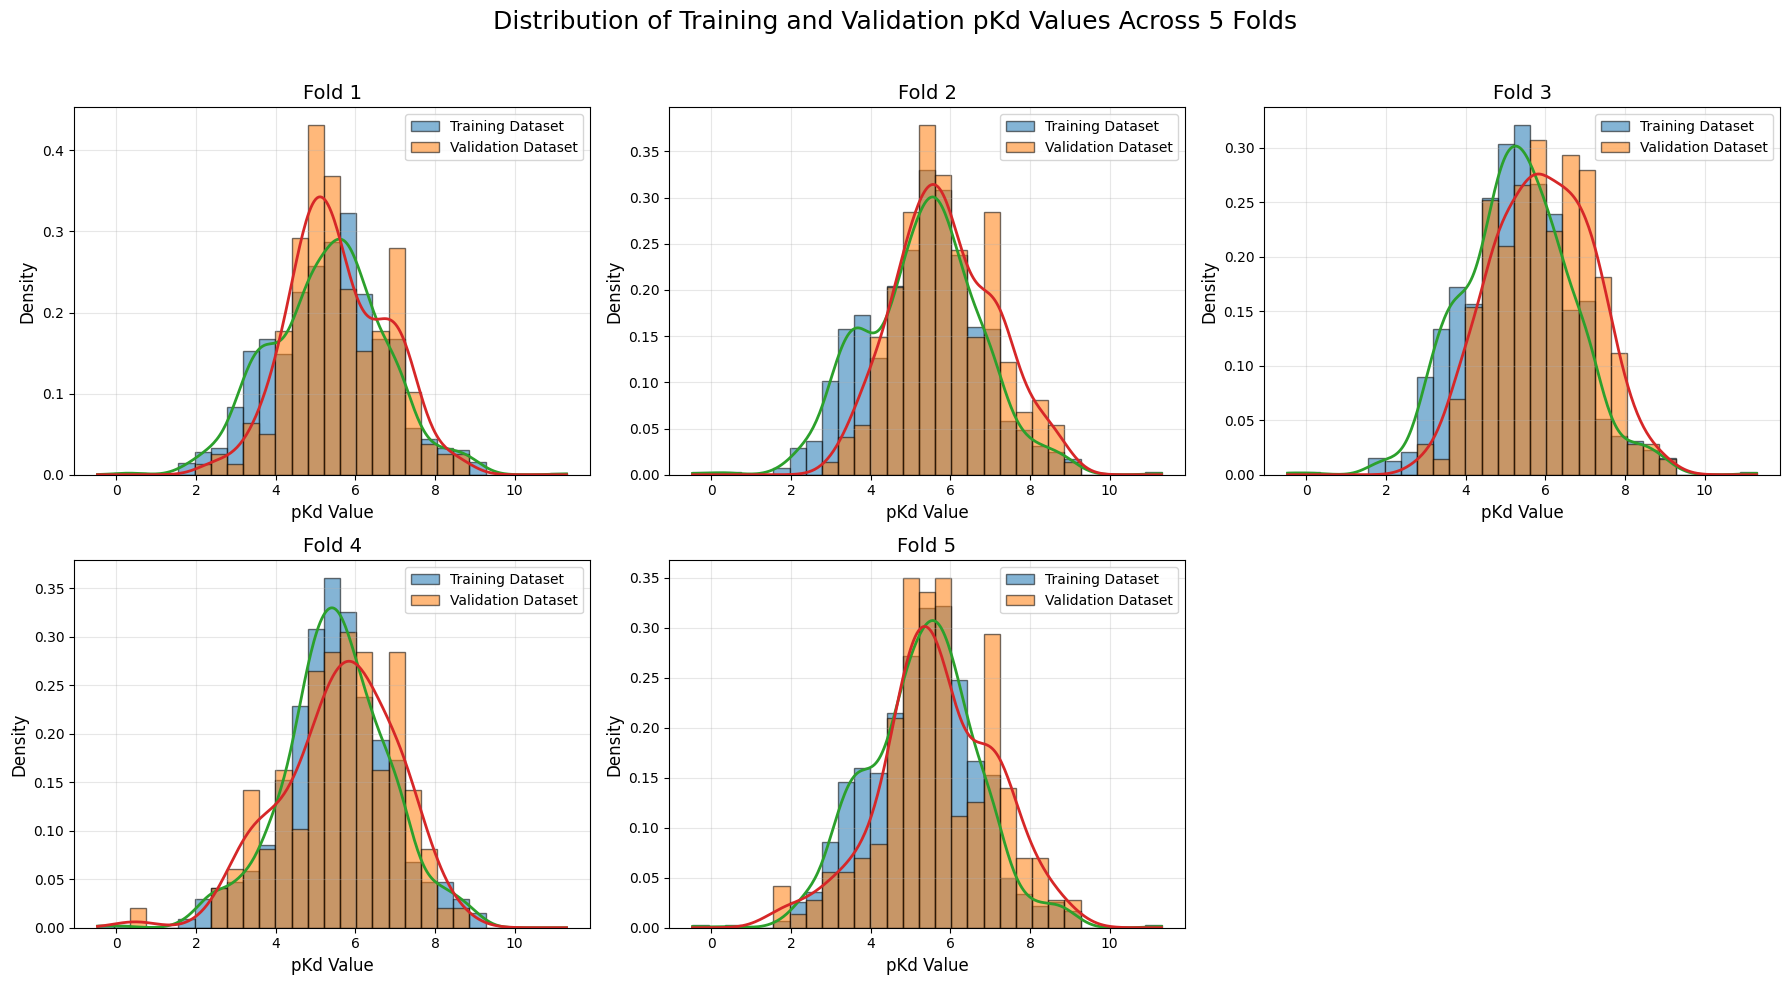

In [42]:
plot_all_folds_train_val_pkd_hist(
    train_val_best_splits
)